In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so
import pingouin as pg

from pymutspec.draw import plot_mutspec12
from pymutspec.annotation import CodonAnnotation
from pymutspec.constants import possible_codons

from calculate_exp_aa_subst_matrix import (
    amino_acid_codes, alphabet, cdn_spectrum_to_matrix, 
    nuc_spectrum_to_matrix, collect_possible_changes,
    get_equilibrium_probabilities
)

In [2]:
coda = CodonAnnotation(2)

## Calculate observed freqs

In [3]:
from Bio import SeqIO

gene = 'Cytb'
# for gene_fn in glob.glob('../../../192/1data_derivation/nemu_input/*.fasta'):
gene_fn = f'../../../192/1data_derivation/nemu_input/{gene}.fasta'
gene_seqs = list(SeqIO.parse(gene_fn, 'fasta'))
sizes = [len(x) for x in gene_seqs]
gene_seqs = [x for x in gene_seqs if len(x) > 370 and len(x) < 385]

plt.figure(figsize=(4, 2))
plt.hist([len(x) for x in gene_seqs], 45)
plt.vlines([370, 385], 0, 2000, 'r', '--')
plt.title(f'{gene} ({len(sizes)}, {len(gene_seqs)})')
plt.show()


/tmp/ipykernel_83161/2273191863.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [4]:
from collections import Counter

obs_aa_freqs = []
for rec in gene_seqs:
    cur_cls = rec.description.split('###')[1].split(';')[1].split('_')[0]
    row = dict(Counter(rec.seq))
    row['cls'] = cur_cls
    row['len'] = len(rec)
    obs_aa_freqs.append(row)

obs_aa_freqs = pd.DataFrame(obs_aa_freqs).fillna(0)
del obs_aa_freqs['B']
del obs_aa_freqs['X']
obs_aa_freqs = obs_aa_freqs[obs_aa_freqs.cls.isin(obs_aa_freqs.cls.value_counts().head().index)].set_index('cls')
obs_aa_freqs = obs_aa_freqs.div(obs_aa_freqs['len'], axis=0)
del obs_aa_freqs['len']
obs_aa_freqs = obs_aa_freqs.melt(ignore_index=False, var_name='aa', value_name='freq').reset_index()
obs_aa_freqs['aa'] = obs_aa_freqs.aa.map(amino_acid_codes)
obs_aa_freqs

,cls,aa,freq
0,Actinopteri,Met,0.031579
1,Actinopteri,Met,0.036842
2,Mammalia,Met,0.031496
3,Mammalia,Met,0.034121
4,Actinopteri,Met,0.028947
...,...,...,...
89915,Aves,Glu,0.018421
89916,Aves,Glu,0.018421
89917,Aves,Glu,0.018421
89918,Aves,Glu,0.018421


In [5]:
obs_aa_freqs['cls'].value_counts()//20

cls
Mammalia        1727
Actinopteri     1630
Aves             551
Lepidosauria     371
Amphibia         217
Name: count, dtype: int64

In [6]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=obs_aa_freqs, x='aa', y='freq', hue='cls', showfliers=True, fliersize=1)

<Axes: xlabel='aa', ylabel='freq'>

## Mean vertebrates spectra

In [7]:
ms12 = pd.read_csv('../../../192/1data_derivation/dataset/MutSpecVertebrates12.csv.gz')
ms12cytb = ms12[ms12.Gene == 'Cytb']
del ms12
ms12cytb


,Gene,Class,Species,Mut,Observed,Expected,MutSpec
2472,Cytb,Mammalia,Tarsius_dentatus,A>C,0.999340,106.150000,0.014561
2473,Cytb,Mammalia,Tarsius_dentatus,A>G,3.711777,162.150000,0.035404
2474,Cytb,Mammalia,Tarsius_dentatus,A>T,NaN,106.150000,0.000000
2475,Cytb,Mammalia,Tarsius_dentatus,C>A,NaN,41.100000,0.000000
2476,Cytb,Mammalia,Tarsius_dentatus,C>G,NaN,41.100000,0.000000
...,...,...,...,...,...,...,...
22831,Cytb,Mammalia,Trinomys_dimidiatus,G>C,0.999150,9.244444,0.098322
22832,Cytb,Mammalia,Trinomys_dimidiatus,G>T,1.000000,9.244444,0.098406
22833,Cytb,Mammalia,Trinomys_dimidiatus,T>A,NaN,32.622222,0.000000
22834,Cytb,Mammalia,Trinomys_dimidiatus,T>C,15.420655,81.044444,0.173094


In [8]:
plot_mutspec12(ms12cytb, title='Cytb', figsize=(5, 3));

/home/kpotoh/AminoAcidShift/.venv/lib/python3.13/site-packages/pymutspec/draw/spectra.py:294: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [9]:
# species_total = ms12cytb.Species.unique()
# nreplics = 100
# fraction = 0.1
# size = int(len(species_total)*fraction)
# eq_freqs_cdn = []
# for i in range(nreplics):
#     df_changes = collect_possible_changes()
#     sampled_species = np.random.choice(species_total, size, replace=False)

#     mean_vert_ms12 = ms12cytb[ms12cytb.Species.isin(sampled_species)]\
#         .groupby(['Mut']).MutSpec.mean().to_dict()
    
#     ## Calculate nucleotide equilibrium frequencies
#     # M = nuc_spectrum_to_matrix(mean_vert_ms12)
#     # eq_prob = get_equilibrium_probabilities(M).astype(float)
#     # nucl_eq = pd.Series(dict(zip(alphabet, eq_prob)))
#     # nucl_eq.name = 'freq'
#     # nucl_eq.index.name = 'nucl'
#     # nucl_eq = nucl_eq.reset_index()
#     # print(nucl_eq)

#     ## Calculate codon and aa equilibrium frequencies
#     df_changes['rate'] = df_changes['sbs'].map(mean_vert_ms12)
#     cdn_sbs = df_changes.groupby(['cdn1', 'cdn2'])['rate'].sum()
#     M = cdn_spectrum_to_matrix(cdn_sbs)
#     eq_prob = get_equilibrium_probabilities(M).astype(float)

#     cur_eq_freqs = pd.Series(dict(zip(possible_codons, eq_prob)))
#     cur_eq_freqs.name = 'freq'
#     cur_eq_freqs.index.name = 'cdn'
#     cur_eq_freqs = cur_eq_freqs.reset_index()
#     cur_eq_freqs['aa'] = cur_eq_freqs['cdn'].map(coda.translate_codon).map(amino_acid_codes)

#     eq_freqs_cdn.append(cur_eq_freqs.assign(rep=i+1))

# eq_freqs_cdn = pd.concat(eq_freqs_cdn)


df_changes = collect_possible_changes()
mean_vert_ms12 = ms12cytb.groupby(['Mut']).MutSpec.mean().to_dict()

## Calculate codon and aa equilibrium frequencies
df_changes['rate'] = df_changes['sbs'].map(mean_vert_ms12)
cdn_sbs = df_changes.groupby(['cdn1', 'cdn2'])['rate'].sum()
M = cdn_spectrum_to_matrix(cdn_sbs)
eq_prob = get_equilibrium_probabilities(M).astype(float)

eq_freqs_cdn = pd.Series(dict(zip(possible_codons, eq_prob)))
eq_freqs_cdn.name = 'freq'
eq_freqs_cdn.index.name = 'cdn'
eq_freqs_cdn = eq_freqs_cdn.reset_index()
eq_freqs_cdn['aa'] = eq_freqs_cdn['cdn'].map(coda.translate_codon).map(amino_acid_codes)

eq_freqs_cdn.to_csv('./data/vert_cdn_eq_freqs.csv', index=False, float_format='%g')
eq_freqs_cdn

/tmp/ipykernel_83161/2897464712.py:46: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob = get_equilibrium_probabilities(M).astype(float)


,cdn,freq,aa
0,AAA,0.079730,Lys
1,AAC,0.055370,Asn
2,AAG,0.015532,Lys
3,AAT,0.034613,Asn
4,ACA,0.055370,Thr
...,...,...,...
59,TGT,0.002927,Cys
60,TTA,0.015027,Leu
61,TTC,0.010436,Phe
62,TTG,0.002927,Leu


In [10]:
# eq_freqs_aa = eq_freqs_cdn[eq_freqs_cdn.aa !='*']\
#     .groupby(['rep', 'aa'])['freq'].sum().unstack()
# eq_freqs_aa = (eq_freqs_aa.T / eq_freqs_aa.sum(1)).T
# eq_freqs_aa = eq_freqs_aa.stack().rename('freq').reset_index()
# eq_freqs_aa.to_csv('./data/vert_aa_eq_freqs_rep100.csv', index=False, float_format='%g')

eq_freqs_aa = eq_freqs_cdn[eq_freqs_cdn.aa !='*'].groupby('aa')['freq'].sum()
eq_freqs_aa /= eq_freqs_aa.sum()
eq_freqs_aa = eq_freqs_aa.sort_values(ascending=False).reset_index()
eq_freqs_aa.to_csv('./data/vert_aa_eq_freqs.csv', index=False)
eq_freqs_aa

,aa,freq
0,Thr,0.136846
1,Lys,0.101334
2,Asn,0.095718
3,Pro,0.095035
4,Leu,0.078508
5,Ser,0.078056
6,Gln,0.070373
7,His,0.066473
8,Met,0.043992
9,Ile,0.041554


In [11]:
plt.figure(figsize=(14, 4))
ax = sns.barplot(eq_freqs_aa, x='aa', y='freq', color='lightgray', 
                 edgecolor=".55", label='Equilibrium')
# ax = sns.boxplot(data=eq_freqs_aa, x='aa', y='freq', showfliers=True, 
#             fliersize=1, label='Equilibrium', color='lightgray')
sns.boxplot(data=obs_aa_freqs, x='aa', y='freq', showfliers=True, 
            fliersize=1, ax=ax, label='Observed', color='lightgreen')
ax.set_title('Vertebrates Cytb')
plt.savefig('./figures/aa_eq_freqs_vert_cytb.pdf')
plt.show()

/tmp/ipykernel_83161/1742148133.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [12]:
_ = eq_freqs_aa.merge(obs_aa_freqs.groupby('aa').freq.mean().reset_index(), 
                                on='aa', suffixes=('_eq', '_obs'))
print(f'Pearson Corr: {_.freq_eq.corr(_.freq_obs):.2f}')
sns.lmplot(data=_,x='freq_eq', y='freq_obs', fit_reg=True, height=3, aspect=1.5);

Pearson Corr: 0.22


### Determine gainers and loosers

In [13]:
aa_freqs_div = obs_aa_freqs.groupby('aa').freq.mean().reset_index()\
    .merge(eq_freqs_aa, on='aa', suffixes=('_obs', '_eq'))
aa_freqs_div['div'] = (aa_freqs_div.freq_eq - aa_freqs_div.freq_obs)# / aa_freqs_div.freq_eq
aa_freqs_div = aa_freqs_div.sort_values('div', ascending=False)
aa_freqs_div.head()

,aa,freq_obs,freq_eq,div
11,Lys,0.024531,0.101334,0.076802
16,Thr,0.065423,0.136846,0.071423
5,Gln,0.017630,0.070373,0.052743
2,Asn,0.047152,0.095718,0.048566
14,Pro,0.058942,0.095035,0.036093


In [14]:
THRESHOLD = 0.02

plt.figure(figsize=(10, 4))
ax = sns.barplot(data=aa_freqs_div, x='aa', y='div', color='lightgray', edgecolor=".65")
for bar in ax.patches:
    if bar.get_height() > THRESHOLD:
        bar.set_color('lightcoral')
        bar.set_edgecolor('0.45')
    if bar.get_height() < -THRESHOLD:
        bar.set_color('lightblue')
        bar.set_edgecolor('0.45')

plt.legend([plt.Rectangle((0,0),1,1,fc="lightcoral", edgecolor = '0.45'), 
            plt.Rectangle((0,0),1,1,fc='lightblue', edgecolor = '0.45')],
           ['Gainers', 'Loosers'], loc='upper right')

plt.title(f'Assignment: dif > {THRESHOLD*100:.1f}% (Vertebrates Cytb)')
plt.ylabel('Frequencies [Equilibrium - Observed]')
plt.savefig('./figures/aa_diff_freqs_vert_cytb.pdf')
plt.show()

/tmp/ipykernel_83161/1941369916.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 5 Mean classes spectra

In [15]:
classes_spectra = ms12cytb.groupby(['Class', 'Mut']).MutSpec.mean().unstack()
classes_spectra

Mut,A>C,A>G,A>T,C>A,C>G,C>T,G>A,G>C,G>T,T>A,T>C,T>G
Class,,,,,,,,,,,,
Actinopteri,0.014435,0.145561,0.013402,0.023053,0.012046,0.095308,0.461847,0.045048,0.017278,0.012928,0.147362,0.011732
Amphibia,0.013185,0.100753,0.019012,0.043678,0.003186,0.150426,0.457255,0.018041,0.019422,0.014543,0.150991,0.009507
Aves,0.008066,0.070300,0.007046,0.021095,0.004004,0.085040,0.464150,0.024109,0.006848,0.008436,0.297659,0.003249
Lepidosauria,0.011596,0.073535,0.012197,0.033103,0.004963,0.094936,0.534351,0.026590,0.026501,0.013173,0.159894,0.009161
Mammalia,0.006995,0.067613,0.012740,0.024510,0.005048,0.124436,0.480826,0.021098,0.019011,0.014834,0.216409,0.006481


In [16]:
classes_spectra.plot(kind='bar', stacked=True, figsize=(6, 5), edgecolor='black')
plt.legend(title='Mutation type', bbox_to_anchor=(1, 1))
plt.ylabel('Mean mutation spectrum')
plt.show()

/tmp/ipykernel_83161/2187979345.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [17]:
data_nucl = []
data_cdn = []

for _cls in classes_spectra.index:
    mean_cls_ms12 = classes_spectra.loc[_cls].to_dict()

    df_changes = collect_possible_changes()

    M = nuc_spectrum_to_matrix(mean_cls_ms12)
    eq_prob_nuc = get_equilibrium_probabilities(M).astype(float)
    nucl_eq = pd.Series(dict(zip(alphabet, eq_prob_nuc)))
    nucl_eq.name = 'freq'
    nucl_eq.index.name = 'nucl'
    nucl_eq = nucl_eq.reset_index().assign(cls=_cls)
    data_nucl.append(nucl_eq)


    df_changes['rate'] = df_changes['sbs'].map(mean_cls_ms12)
    cdn_sbs = df_changes.groupby(['cdn1', 'cdn2'])['rate'].sum()
    M = cdn_spectrum_to_matrix(cdn_sbs)
    eq_prob_cdn = get_equilibrium_probabilities(M).astype(float)

    eq_freqs = pd.Series(dict(zip(possible_codons, eq_prob_cdn)))
    eq_freqs.name = 'freq'
    eq_freqs.index.name = 'cdn'
    eq_freqs = eq_freqs.reset_index().assign(cls=_cls)
    eq_freqs['aa'] = eq_freqs['cdn'].map(coda.translate_codon).map(amino_acid_codes)
    data_cdn.append(eq_freqs)

/tmp/ipykernel_83161/4144104991.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_nuc = get_equilibrium_probabilities(M).astype(float)


/tmp/ipykernel_83161/4144104991.py:21: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_cdn = get_equilibrium_probabilities(M).astype(float)
/tmp/ipykernel_83161/4144104991.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_nuc = get_equilibrium_probabilities(M).astype(float)
/tmp/ipykernel_83161/4144104991.py:21: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_cdn = get_equilibrium_probabilities(M).astype(float)
/tmp/ipykernel_83161/4144104991.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_nuc = get_equilibrium_probabilities(M).astype(float)
/tmp/ipykernel_83161/4144104991.py:21: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_cdn = get_equilibrium_probabilities(M).astype(float)
/tmp/ipykernel_83161/4144104991.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
 

/tmp/ipykernel_83161/4144104991.py:21: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_cdn = get_equilibrium_probabilities(M).astype(float)
/tmp/ipykernel_83161/4144104991.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_nuc = get_equilibrium_probabilities(M).astype(float)


/tmp/ipykernel_83161/4144104991.py:21: ComplexWarning: Casting complex values to real discards the imaginary part
  eq_prob_cdn = get_equilibrium_probabilities(M).astype(float)


In [18]:
df_cdn = pd.concat(data_cdn)
df_nucl = pd.concat(data_nucl)

df_aa_wide = df_cdn[df_cdn.aa !='*'].groupby(['cls', 'aa'])['freq'].sum().unstack()
df_aa_wide = (df_aa_wide.T / df_aa_wide.sum(1)).T
df_aa = df_aa_wide.stack().rename('freq').reset_index()

df_nucl.to_csv('./data/nucl_eq_freqs_cls.csv', index=False)
df_cdn.to_csv('./data/cdn_eq_freqs_cls.csv', index=False)
df_aa.to_csv('./data/aa_eq_freqs_cls.csv', index=False)

/tmp/ipykernel_83161/3970161043.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  df_aa_wide = (df_aa_wide.T / df_aa_wide.sum(1)).T


In [19]:
df_aa

,cls,aa,freq
0,Actinopteri,Ala,0.037339
1,Actinopteri,Arg,0.037339
2,Actinopteri,Asn,0.070308
3,Actinopteri,Asp,0.021973
4,Actinopteri,Cys,0.013541
...,...,...,...
95,Mammalia,Ser,0.068543
96,Mammalia,Thr,0.142229
97,Mammalia,Trp,0.006849
98,Mammalia,Tyr,0.041229


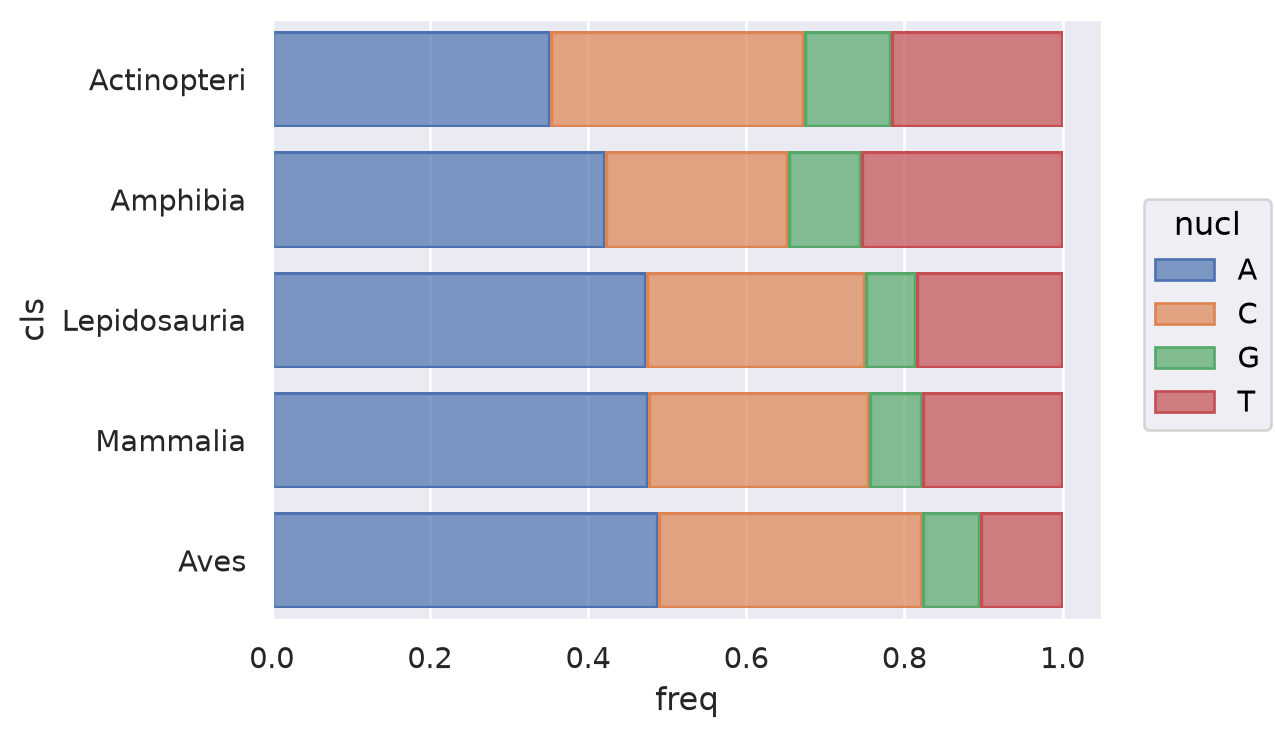

In [20]:
order=['Actinopteri', 'Amphibia', 'Lepidosauria', 'Mammalia', 'Aves']

so.Plot(df_nucl.set_index('cls').loc[order].reset_index(), 
        y="cls", x='freq', color="nucl"
).add(so.Bar(), so.Stack()).layout(size=(6,4)).save('figures/nuc_eq_freqs_cls.pdf')

In [21]:
_ = df_aa.pivot(index='cls', columns='aa', values='freq').loc[order]*100

plt.figure(figsize=(16, 4))
sns.heatmap(_.loc[:,_.mean(0).sort_values(ascending=False).index], 
            cmap='coolwarm', annot=True, cbar_kws={'label': 'Equilibrium frequency (%)'})
plt.ylabel('')
plt.xlabel('')
plt.savefig('figures/aa_eq_freqs_cls_heatmap.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_83161/3014550882.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  sns.heatmap(_.loc[:,_.mean(0).sort_values(ascending=False).index],


/tmp/ipykernel_83161/3014550882.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [22]:
import warnings
warnings.filterwarnings("ignore")

order=['Actinopteri', 'Amphibia', 'Lepidosauria', 'Mammalia', 'Aves'][::-1]
_ = df_aa.pivot(index='cls', columns='aa', values='freq').loc[order]*100

# plt.figure(figsize=(10, 3.5))
fig, axs = plt.subplots(5, 1, figsize=(10, 3.5*5), sharey=True)
for i, _cls in enumerate(order):
    ax = sns.barplot(data=df_aa[df_aa.cls == _cls], x='aa', y='freq', 
                color='lightgray', edgecolor=".55", order=_.mean(0).sort_values(ascending=False).index, ax=axs[i])
    sns.boxplot(data=obs_aa_freqs[obs_aa_freqs.cls == _cls], x='aa', y='freq', showfliers=True,
                fliersize=1, ax=ax, label='Observed', color='lightgreen')
    
    ax.set_title(_cls)
plt.tight_layout()
plt.savefig('figures/aa_eq_obs_freqs_5cls.pdf', bbox_inches='tight')
plt.show()

In [23]:
import scipy 

_ = df_aa.merge(obs_aa_freqs.groupby(['cls', 'aa']).freq.mean().reset_index(), 
                                on=['cls','aa'], suffixes=('_eq', '_obs'))
print('pearsonr')
for _cls in order[::-1]:
    res = scipy.stats.pearsonr(_.loc[_.cls == _cls].freq_eq, _.loc[_.cls == _cls].freq_obs)
    print(f'{_cls}: {res[0]:.2f}, p-value: {res[1]:.2f}')
g = sns.lmplot(data=_,x='freq_eq', y='freq_obs', col='cls', col_wrap=3, sharey=False, sharex=False,
           fit_reg=True, height=3, aspect=1)
g.savefig('figures/aa_eq_obs_freqs_5cls_lmplot.pdf', bbox_inches='tight')
plt.show()

pearsonr
Actinopteri: 0.36, p-value: 0.11
Amphibia: 0.40, p-value: 0.08
Lepidosauria: 0.29, p-value: 0.22
Mammalia: 0.15, p-value: 0.54
Aves: 0.06, p-value: 0.81


### Determine gainers and loosers

In [24]:
df_aa.merge(obs_aa_freqs.groupby(['cls', 'aa']).freq.mean().reset_index(), 
                                on=['cls','aa'], suffixes=('_eq', '_obs'))

,cls,aa,freq_eq,freq_obs
0,Actinopteri,Ala,0.037339,0.083088
1,Actinopteri,Arg,0.037339,0.020970
2,Actinopteri,Asn,0.070308,0.047163
3,Actinopteri,Asp,0.021973,0.028136
4,Actinopteri,Cys,0.013541,0.008380
...,...,...,...,...
95,Mammalia,Ser,0.068543,0.063894
96,Mammalia,Thr,0.142229,0.067377
97,Mammalia,Trp,0.006849,0.030968
98,Mammalia,Tyr,0.041229,0.040211


In [25]:
aa_freqs_div = df_aa.merge(obs_aa_freqs.groupby(['cls', 'aa']).freq.mean().reset_index(), 
                                on=['cls','aa'], suffixes=('_eq', '_obs'))
aa_freqs_div['div'] = (aa_freqs_div.freq_eq - aa_freqs_div.freq_obs)# / aa_freqs_div.freq_eq
aa_freqs_div = aa_freqs_div.sort_values(['cls', 'div'], ascending=False)
aa_freqs_div.head(10)

,cls,aa,freq_eq,freq_obs,div
91,Mammalia,Lys,0.131018,0.024426,0.106592
96,Mammalia,Thr,0.142229,0.067377,0.074853
82,Mammalia,Asn,0.110529,0.043814,0.066715
85,Mammalia,Gln,0.077147,0.016965,0.060181
88,Mammalia,His,0.065082,0.032450,0.032632
94,Mammalia,Pro,0.083748,0.059633,0.024115
92,Mammalia,Met,0.048872,0.039818,0.009053
95,Mammalia,Ser,0.068543,0.063894,0.004649
86,Mammalia,Glu,0.018361,0.015539,0.002822
98,Mammalia,Tyr,0.041229,0.040211,0.001018


In [26]:
THRESHOLD = 0.02

plt.figure(figsize=(10, 4))
loosers_lst = []
gainers_lst = []
fig, axs = plt.subplots(5, 1, figsize=(10, 3.5*5), sharey=True)
for i, _cls in enumerate(order[::-1]):
    ax = sns.barplot(data=aa_freqs_div[aa_freqs_div['cls'] == _cls], ax=axs[i],
                     x='aa', y='div', color='lightgray', edgecolor=".65")
    for j, bar in enumerate(ax.patches):
        if bar.get_height() > THRESHOLD:
            gainers_lst.append(ax.get_xticklabels()[j].get_text())
            bar.set_color('lightcoral')
            bar.set_edgecolor('0.45')
        if bar.get_height() < -THRESHOLD:
            loosers_lst.append(ax.get_xticklabels()[j].get_text())
            bar.set_color('lightblue')
            bar.set_edgecolor('0.45')

    ax.legend([plt.Rectangle((0,0),1,1,fc="lightcoral", edgecolor = '0.45'), 
                plt.Rectangle((0,0),1,1,fc='lightblue', edgecolor = '0.45')],
            ['Gainers', 'Loosers'], loc='upper right')

    ax.set_title(f'Assignment: dif > {THRESHOLD*100:.1f}% ({_cls} Cytb)')
    ax.set_ylabel('Frequencies [Equilibrium - Observed]')

plt.tight_layout()
plt.savefig('figures/aa_diff_freqs_5cls_cytb.pdf', bbox_inches='tight');

In [27]:
from collections import Counter

print('gainers tier list:')
pd.Series(Counter(gainers_lst)).sort_values(ascending=False)

gainers tier list:


Thr    5
Gln    5
Lys    5
Asn    5
His    5
Pro    4
Ser    1
Met    1
Tyr    1
dtype: int64

In [28]:
[x for x in Counter(loosers_lst)]

['Trp', 'Ile', 'Val', 'Ala', 'Phe', 'Gly', 'Leu']

In [29]:
print('loosers tier list')
pd.Series(Counter(loosers_lst)).sort_values(ascending=False)

loosers tier list


Ile    5
Val    5
Ala    5
Gly    5
Phe    5
Leu    5
Trp    4
dtype: int64

In [30]:
freq_div = obs_aa_freqs.groupby(['cls', 'aa']).freq.mean().reset_index()\
    .merge(df_aa, on=['cls', 'aa'], suffixes=('_obs', '_eq'))

freq_div['div'] = freq_div.freq_obs / freq_div.freq_eq
sns.kdeplot(freq_div, x='div', hue='cls', fill=True)
plt.vlines(1, 0, 0.077, 'r', '--', label='One')
plt.title('Vertebrates Cytb')
plt.xlabel('Observed / Equilibrium')
plt.show()

## Expected AA subst

In [31]:
aa_subst_vert = pd.read_csv('data/exp_aa_subst_vert.csv')

aa_subst_vert_matrix = aa_subst_vert.reset_index()\
    .pivot(index='aa1', columns='aa2', values='rate').fillna(0.)

In [32]:
fig, axs = plt.subplots(2, 3, figsize=(12, 10), 
                        width_ratios=[0.1, 1, .05], height_ratios=[1, 0.1])
sns.heatmap(aa_subst_vert_matrix, annot=True, fmt=".2f", ax=axs[0, 1], cbar_ax=axs[0, 2],
            cmap='coolwarm', cbar_kws={'label': 'Substitution rate'}
)
axs[0, 1].set_ylabel('')
axs[0, 1].set_xlabel('')
axs[0, 1].set_xticks([])
axs[0, 1].set_yticks([])
axs[0, 1].set_title('Expected substitution rates between amino acids in Vertebrates Cytb')


freqs_from = aa_subst_vert_matrix.sum(1) - aa_subst_vert_matrix.values.diagonal()
sns.barplot(freqs_from.reset_index(), y='aa1', x=0, ax=axs[0, 0],
            color='lightgray', edgecolor='black')
axs[0, 0].set_ylabel('From')
axs[0, 0].set_xlabel('')
axs[0, 0].spines['top'].set_visible(False)
axs[0, 0].spines['right'].set_visible(False)
axs[0, 0].spines['bottom'].set_visible(False)
axs[0, 0].spines['left'].set_visible(False)
axs[0, 0].invert_xaxis()
axs[0, 0].set_xticks([])


freqs_to = aa_subst_vert_matrix.sum(0) - aa_subst_vert_matrix.values.diagonal()
sns.barplot(freqs_to.reset_index(), x='aa2', y=0, ax=axs[1, 1],
            color='lightgray', edgecolor='black')
axs[1, 1].set_ylabel('')
axs[1, 1].set_xlabel('To')
axs[1, 1].spines['top'].set_visible(False)
axs[1, 1].spines['right'].set_visible(False)
axs[1, 1].spines['bottom'].set_visible(False)
axs[1, 1].spines['left'].set_visible(False)
axs[1, 1].invert_yaxis()
axs[1, 1].set_yticks([])

axs[1, 0].remove()
axs[1, 2].remove()

plt.tight_layout()
plt.savefig('figures/exp_aa_subst_vert_matrix.pdf')
plt.show()

In [33]:
THRESHOLD = 0.5

freqs_to.index.name = 'aa'
freqs_from.index.name = 'aa'

plt.figure(figsize=(10, 4))
ax = sns.barplot((freqs_to - freqs_from).sort_values(ascending=False), color='lightgray', edgecolor=".65")
for bar in ax.patches:
    if bar.get_height() > 1.5:
        bar.set_color('orangered')
        bar.set_edgecolor('0.45')
    elif bar.get_height() > THRESHOLD:
        bar.set_color('lightcoral')
        bar.set_edgecolor('0.45')
    elif bar.get_height() < -1.5:
        bar.set_color('royalblue')
        bar.set_edgecolor('0.45')
    elif bar.get_height() < -THRESHOLD:
        bar.set_color('lightblue')
        bar.set_edgecolor('0.45')

plt.legend([
    plt.Rectangle((0,0),1,1,fc="orangered", edgecolor = '0.45'), 
    plt.Rectangle((0,0),1,1,fc="lightcoral", edgecolor = '0.45'), 
    plt.Rectangle((0,0),1,1,fc='lightblue', edgecolor = '0.45'),
    plt.Rectangle((0,0),1,1,fc='royalblue', edgecolor = '0.45'),
    ],[
        'Top Gainers', 'Gainers', 'Loosers', 'Top Loosers'], 
    loc='upper right')

plt.title(f'Expected aa subst based assignment (Vertebrates Cytb)')
plt.ylabel('Rates [To - From]')
plt.savefig('./figures/aa_diff_rates_vert_cytb.pdf')
plt.show()